# Vélib' sous tension — Question A: *departure impossible*

**Question.** For each of the 80 stations, predict **30 and 60 minutes ahead** whether the station will have
**fewer than 2 bikes available** (`bikes_available < 2`, "departure impossible"). One common model for all stations.
References: the majority class and **persistence** (the future state equals the current state).

**Protocol.** Strictly chronological split — train (25 Aug → the 28 h collection outage of 23–24 Sep),
validation (24 Sep 13:45 UTC → 1 Oct 00:00 Paris time), test (1 → 8 Oct). Hyper-parameters, decision
thresholds and the final model are chosen on validation only and frozen before the test week is scored, once.
Every preprocessing step is fitted on train; every lag is computed per station on a regular 15-min grid;
calendar features use Paris local time.

All the logic lives in `src/velib/` (one module per step) and is covered by `tests/test_leakage_guards.py`; this
notebook is the commented walk-through and calls the same functions as `scripts/run_pipeline.py`, which writes the
reference tables to `reports/results/`. The notebook writes its own figures to `notebooks/figures/` only.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "velib").is_dir())
sys.path.insert(0, str(ROOT / "src"))

import json

import numpy as np
import pandas as pd
from IPython.display import Image, display

from velib import evaluation as ev
from velib import experiments, plots, quality
from velib.config import HORIZONS, LOCAL_TZ
from velib.data import fetch, md5sum
from velib.features import FEATURES
from velib.grid import n_unaligned
from velib.pipeline import ablation, build_all, evaluate, prepare, select_models
from velib.split import population_table, summary

pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
FIGURES = ROOT / "notebooks" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
RUN_EXTRAS = False  # True: also run the appendix experiments (several more minutes)
GROUP_COLS = ["n", "prevalence", "pr_auc", "precision", "recall", "f1"]
SUSPECT_STATION = 45504

## 1. Data: download once, verify the md5

The frozen file is not versioned. `fetch()` downloads it only if `data/` does not contain it yet, and always checks
its md5 against the published one (`02ab1e3fdac10579e4ce93d1540a5dc7`) before anything else.

In [2]:
path = fetch()
print(path.name, md5sum(path))
raw, grid = prepare(path)  # raw snapshots, and the regular (station x 15 min) grid with all features
q = quality.report(raw)
q["coverage"]

velib-2026-10-08.csv.gz 02ab1e3fdac10579e4ce93d1540a5dc7


rows                                              329680
stations                                              80
snapshots                                           4139
first_snapshot_utc             2026-08-25 11:57:26+00:00
last_snapshot_utc              2026-10-08 20:15:01+00:00
rows_per_station_min                                4121
rows_per_station_max                                4121
duplicated_station_snapshot                            0
dtype: object

## 2. Data quality: described, not hidden

The brief asks that outages, closures and incoherent values be counted and described. Nothing below modifies the data.

In [3]:
display(q["missing_values"].to_frame("missing"), q["consistency"].to_frame("rows"),
        q["over_capacity_by_station"].to_frame("rows with bikes + docks > capacity"))

,missing
capacity,1920


,rows
bikes != mechanical + electric,0
bikes + docks > capacity,2256
bikes + docks < capacity (unavailable docks),168340
capacity missing,1920
bikes + docks == 0,0


,rows with bikes + docks > capacity
station_code,
45504,1641
9104,400
40007,145
20006,57
21030,5


* `capacity` is missing in 26 snapshots, but it is **constant within each station** (checked in `grid.py`),
  so it is a static attribute and filling it is not a look-ahead.
* `bikes + docks > capacity` is concentrated on a few stations (45504 alone accounts for ~73 %): the declared
  capacity is unreliable there, which is why the fill ratio uses `bikes / (bikes + docks)` rather than `capacity`.
* `bikes + docks < capacity` in about half of the rows simply reflects docks out of service.

In [4]:
q["collection_gaps"]

,start,end,minutes
2771,2026-09-23 09:45:01+00:00,2026-09-24 13:45:03+00:00,1680.033
78,2026-08-26 07:00:02+00:00,2026-08-26 07:30:07+00:00,30.083
3437,2026-10-01 12:15:01+00:00,2026-10-01 12:45:02+00:00,30.017
253,2026-08-28 03:00:01+00:00,2026-08-28 03:30:01+00:00,30.000
1877,2026-09-14 01:30:02+00:00,2026-09-14 02:00:02+00:00,30.000
2421,2026-09-19 17:45:01+00:00,2026-09-19 18:15:01+00:00,30.000
3410,2026-10-01 05:15:01+00:00,2026-10-01 05:45:01+00:00,30.000
3987,2026-10-07 06:00:01+00:00,2026-10-07 06:30:01+00:00,30.000
2428,2026-09-19 19:45:02+00:00,2026-09-19 20:15:01+00:00,29.983
1874,2026-09-14 00:30:02+00:00,2026-09-14 01:00:01+00:00,29.983


In [5]:
sets_table, complementary = q["partial_snapshot_sets"]
print(f"{len(q['partial_snapshots'])} incomplete snapshots; distinct station sets disjoint and covering the 80 stations: {complementary}")
sets_table

36 incomplete snapshots; distinct station sets disjoint and covering the 80 stations: True


,stations in the set,snapshots,of which Paris
0,30,18,17
1,50,18,33


* One **28-hour outage** (23 Sep 09:45 → 24 Sep 13:45 UTC) and nine 30-minute gaps (one missed snapshot each).
* 36 **incomplete snapshots**: they contain either always the same 30 stations or always the complementary 50.
  The same block of stations is missing each time, so this is a truncated collection, not a sample. It is *not* a
  Paris / suburbs split either (both sets mix the two areas), so the hypothesis tested in the first version of the
  notebook is rejected.
* On the regular grid, a station missing from a snapshot is simply an **unobserved slot (NaN)**: no interpolation,
  no forward fill, and lags that point to it are NaN.

In [6]:
q["closure_episodes"]

,station_code,episode,start,end,n_snapshots
0,4101,1,2026-09-19 22:00:02+00:00,2026-09-19 22:00:02+00:00,1
1,4101,2,2026-09-19 22:30:02+00:00,2026-09-20 23:15:01+00:00,100
2,4101,3,2026-09-28 19:30:01+00:00,2026-09-28 20:00:02+00:00,3
3,4101,4,2026-09-28 20:30:02+00:00,2026-09-29 20:30:02+00:00,97
4,4101,5,2026-10-02 22:45:01+00:00,2026-10-02 23:00:02+00:00,2
5,4101,6,2026-10-02 23:30:02+00:00,2026-10-03 22:45:02+00:00,94
6,6030,1,2026-09-24 19:30:01+00:00,2026-09-26 21:30:01+00:00,198
7,8046,1,2026-09-24 13:45:03+00:00,2026-09-26 21:30:01+00:00,221
8,10017,1,2026-10-07 20:15:01+00:00,2026-10-08 20:00:02+00:00,96


In [7]:
static = q["static_stations"]
print(f"median share of unchanged consecutive snapshots over the 80 stations: {static['unchanged_share'].median():.2f}")
static.head(5)

median share of unchanged consecutive snapshots over the 80 stations: 0.38


,unchanged_share,longest_unchanged_run
station_code,,
45504,0.891,180
40007,0.767,52
23702,0.730,51
23805,0.724,54
25008,0.717,59


In [8]:
print("collected_at_utc - source_updated_at (minutes):")
display(q["source_staleness_minutes"].to_frame().T)
print("rows whose source timestamp did not change while the bike count did:", q["unchanged_source_but_bikes_changed"])

collected_at_utc - source_updated_at (minutes):


,count,mean,std,min,50%,90%,99%,max
0,329680.0,64.266,31.875,4.133,61.717,98.183,150.467,1194.733


rows whose source timestamp did not change while the bike count did: 91373


* Four stations were **closed** (`is_renting = is_returning = 0`) for a total of 812 rows, in long episodes (1–2 days).
  A closure is a different phenomenon from running out of bikes: samples from a closed station are excluded from
  the population and **counted** (section 3), and section 8 checks that the choice does not matter. A closed station
  mostly reports 0 bikes, so closed slots are not used as lag sources either (section 5).
* Station 45504 almost never changes state and has most of the `bikes + docks > capacity` rows: it may be frozen in
  the feed. It never has fewer than 2 bikes, so it only adds easy negatives. It is **kept and described**, and
  section 8 shows the test results without it.
* `source_updated_at` lags the collection by ~1 h and often does not move while the bike count does: it is not a
  reliable freshness signal and is not used as a feature.

## 3. Regular grid, exact target and population

* Grid: one row per (station, 15-min UTC slot) — 80 × 4,258 slots. Only the first snapshot (11:57 UTC, not aligned)
  is dropped; all others are collected 1–7 s after a quarter hour.
* **Target**: `y(station, t) = 1` if `bikes_available(station, t + h) < 2`, with `h` = 30 or 60 min, read with a
  per-station `shift(-h)` on the grid (same station, exactly `h` later).
* **Population**: the station is observed and open at `t`, observed and open at `t + h`, and `t + h` falls in the same
  block as `t`. Each grid slot is counted below under the first reason that excludes it.

In [9]:
print("raw rows dropped because not aligned on a quarter hour:", n_unaligned(raw))
for h, steps in HORIZONS.items():
    print(f"horizon {h} min")
    display(population_table(grid, steps))

raw rows dropped because not aligned on a quarter hour: 80
horizon 30 min


block of t,train,val,test,total
reason,,,,
not observed at t,10240,240,560,11040
closed at t,101,519,192,812
not observed at t+h,1490,184,629,2303
closed at t+h,2,5,5,12
t+h in the next block,0,160,0,160
kept,219127,47612,59574,326313


horizon 60 min


block of t,train,val,test,total
reason,,,,
not observed at t,10240,240,560,11040
closed at t,101,519,192,812
not observed at t+h,1470,156,877,2503
closed at t+h,4,8,8,20
t+h in the next block,0,320,0,320
kept,219145,47477,59323,325945


Target distribution. The breakdowns by hour, area and station use the **training block only**. The weekly series
uses train and validation, never the test week, so nothing about the test labels informs the modelling choices.

In [10]:
data = build_all(grid)
tr30 = data[30]["train"]
hour = tr30.index.get_level_values("t").tz_convert(LOCAL_TZ).hour  # Paris local time
display(tr30.groupby(hour)["y"].mean().rename("positive rate by hour (Paris), train").to_frame().T)
display(tr30.groupby(np.where(tr30["paris"] == 1, "Paris", "suburbs"))["y"].mean().rename("positive rate, train").to_frame())
display(tr30.groupby(level="station_code")["y"].mean().describe().rename("positive rate per station, train").to_frame().T)
trval = pd.concat([data[30]["train"], data[30]["val"]])
week = trval.index.get_level_values("t").tz_convert(LOCAL_TZ).isocalendar().week.to_numpy()
trval.groupby(week)["y"].mean().rename("positive rate by ISO week (train + validation)").to_frame().T

t,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
"positive rate by hour (Paris), train",0.081,0.079,0.08,0.08,0.086,0.088,0.08,0.085,0.098,0.127,...,0.121,0.118,0.122,0.122,0.115,0.109,0.11,0.091,0.082,0.078


,"positive rate, train"
Paris,0.118
suburbs,0.078


,count,mean,std,min,25%,50%,75%,max
"positive rate per station, train",80.0,0.103,0.112,0.0,0.012,0.058,0.156,0.458


,35,36,37,38,39,40
positive rate by ISO week (train + validation),0.086,0.1,0.112,0.108,0.117,0.133


## 4. Chronological split

A sample is kept only if `t` and `t + h` fall in the same block, so no training label is observed during validation
and no validation label during the test week. The test block's positive rate stays hidden until the model is chosen.
The training block includes the end of the summer holidays and the positive rate drifts upward week after week
(section 3): a non-stationarity to keep in mind.

`bikes_24h` is missing much more often on validation, because its first day follows the 28 h outage.

In [11]:
for h, sets in data.items():
    print(f"horizon {h} min")
    display(summary(sets))
pd.DataFrame({b: s["bikes_24h"].isna().mean() for b, s in data[30].items()}, index=["bikes_24h missing (30 min)"])

horizon 30 min


,samples,positive rate,from (UTC),to (UTC)
train,219127,0.103,2026-08-25 12:00:00+00:00,2026-09-23 09:15:00+00:00
val,47612,0.126,2026-09-24 13:45:00+00:00,2026-09-30 21:15:00+00:00
test,59574,(hidden),2026-09-30 22:00:00+00:00,2026-10-08 19:45:00+00:00


horizon 60 min


,samples,positive rate,from (UTC),to (UTC)
train,219145,0.103,2026-08-25 12:00:00+00:00,2026-09-23 08:45:00+00:00
val,47477,0.126,2026-09-24 13:45:00+00:00,2026-09-30 20:45:00+00:00
test,59323,(hidden),2026-09-30 22:00:00+00:00,2026-10-08 19:15:00+00:00


,train,val,test
bikes_24h missing (30 min),0.041,0.169,0.011


## 5. Features (all available at prediction time t)

| group | features | how |
|---|---|---|
| state | `bikes_available`, `docks_available`, `fill` | current snapshot; `fill = bikes / (bikes + docks)` |
| trend | `d_bikes_15/30/60`, `bikes_24h` | per-station `shift(k)` on the regular grid, from open slots only (NaN across gaps and closures) |
| calendar | `hour_sin/cos`, `dow`, `weekend` | **Paris local time** (`tz_convert("Europe/Paris")`) |
| station | `capacity`, `paris`, `latitude`, `longitude`, `st_empty_rate` | static; `st_empty_rate` = share of empty slots on the training block, one constant per station |

`st_empty_rate` is deliberately not computed "out of fold". A leave-one-week-out rate is, within a station, almost the
mirror image of that week's own empty rate. Since the trees can also identify the station from its coordinates, they
would decode each training row's own-week labels, a pattern that does not exist on new weeks.

k-NN and naive Bayes do not use `dow`: coded 0–6 it would be read as an ordered distance (Sunday "far" from Monday).

In [12]:
display(tr30[FEATURES].isna().mean().rename("missing share (train)").to_frame().T)
tr30.groupby(pd.cut(tr30["bikes_available"], [-1, 0, 1, 2, 4, 8, 100]), observed=True)["y"].mean().rename(
    "P(y = 1 | bikes now), train").to_frame().T

,bikes_available,docks_available,fill,d_bikes_15,d_bikes_30,d_bikes_60,bikes_24h,hour_sin,hour_cos,dow,weekend,capacity,paris,latitude,longitude,st_empty_rate
missing share (train),0.0,0.0,0.0,0.006,0.006,0.006,0.041,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


bikes_available,"(-1, 0]","(0, 1]","(1, 2]","(2, 4]","(4, 8]","(8, 100]"
"P(y = 1 | bikes now), train",0.832,0.653,0.241,0.089,0.018,0.002


## 6. Model selection on validation (the test week is not touched)

`select_models` runs the same code as the script. For each horizon:
* `k` (k-NN) and the depth (tree) maximise the validation PR-AUC;
* the weighted k-NN uses feature weights learned **inside the training block** (permutation importance of a forest,
  with the last training week held out);
* each ML model gets the F1-optimal threshold on validation;
* the final model is the ML model with the best validation PR-AUC.

These validation figures are **selection** figures, optimistic by construction. The choices are then frozen.

In [13]:
fitted, val, selection = select_models(data)
for h in HORIZONS:
    print(f"horizon {h} min — chosen on validation: {selection[h]['chosen_model']}")
    display(val[val["horizon_min"] == h].drop(columns=["family", "n", "positives", "prevalence", "horizon_min"]).set_index("model"))
print(json.dumps({h: {k: v for k, v in s.items() if k != "knn_weights"} for h, s in selection.items()}, indent=1, default=float))

horizon 30 min — chosen on validation: random forest


,threshold,pr_auc,precision,recall,f1,tp,fp,fn,tn,seconds
model,,,,,,,,,,
majority class,NaN,0.126,NaN,0.000,0.000,0,0,5993,41619,0.0
persistence,NaN,0.707,0.734,0.735,0.734,4404,1598,1589,40021,0.0
naive Bayes,0.970,0.626,0.543,0.777,0.639,4659,3929,1334,37690,0.4
k-NN (k=50),0.260,0.701,0.556,0.784,0.651,4699,3752,1294,37867,38.6
weighted k-NN (k=50),0.400,0.805,0.730,0.748,0.739,4483,1659,1510,39960,10.2
decision tree (depth=8),0.304,0.811,0.700,0.791,0.743,4743,2032,1250,39587,1.7
random forest,0.339,0.828,0.715,0.786,0.749,4711,1874,1282,39745,10.2
gradient boosting,0.334,0.823,0.709,0.787,0.746,4718,1936,1275,39683,3.5


horizon 60 min — chosen on validation: gradient boosting


,threshold,pr_auc,precision,recall,f1,tp,fp,fn,tn,seconds
model,,,,,,,,,,
majority class,NaN,0.126,NaN,0.000,0.000,0,0,5979,41498,0.0
persistence,NaN,0.629,0.664,0.665,0.665,3979,2013,2000,39485,0.0
naive Bayes,0.920,0.562,0.466,0.794,0.588,4750,5436,1229,36062,0.4
k-NN (k=50),0.280,0.670,0.556,0.717,0.626,4285,3427,1694,38071,39.9
weighted k-NN (k=50),0.340,0.738,0.638,0.726,0.679,4341,2459,1638,39039,8.8
decision tree (depth=8),0.330,0.743,0.654,0.710,0.681,4247,2247,1732,39251,1.7
random forest,0.325,0.766,0.653,0.735,0.691,4392,2332,1587,39166,9.8
gradient boosting,0.324,0.767,0.651,0.741,0.693,4432,2374,1547,39124,3.6


{
 "30": {
  "chosen_model": "random forest",
  "knn_k": 50,
  "tree_depth": 8,
  "knn_val_pr_auc": {
   "5": 0.6084076195934436,
   "15": 0.6793762176008257,
   "50": 0.7014299145172563,
   "150": 0.6827646855576692
  },
  "tree_val_pr_auc": {
   "4": 0.7688285554717356,
   "8": 0.8113120542079424,
   "12": 0.8085714064950239,
   "16": 0.8030231141142692
  },
  "thresholds": {
   "naive Bayes": 0.9697520411654957,
   "k-NN (k=50)": 0.26,
   "weighted k-NN (k=50)": 0.4,
   "decision tree (depth=8)": 0.30425531914893617,
   "random forest": 0.3386672749071146,
   "gradient boosting": 0.3341802890693796
  }
 },
 "60": {
  "chosen_model": "gradient boosting",
  "knn_k": 50,
  "tree_depth": 8,
  "knn_val_pr_auc": {
   "5": 0.5664134752374956,
   "15": 0.6387459274938727,
   "50": 0.6703327443565119,
   "150": 0.6571723050490682
  },
  "tree_val_pr_auc": {
   "4": 0.6787802445659756,
   "8": 0.742600166339236,
   "12": 0.7368341848746293,
   "16": 0.7325486060081959
  },
  "thresholds": {
 

## 7. Final evaluation on the test week (frozen models and thresholds)

In [14]:
outputs = {}
for h, sets in data.items():
    te = sets["test"]
    display(summary({"test": te}, show_test_labels=True))
    table, outputs[h] = evaluate(fitted[h], te)
    print(f"horizon {h} min — test week")
    display(table.drop(columns=["family", "n", "positives", "prevalence"]).set_index("model"))
    pers = table.set_index("model").loc["persistence"]
    chosen = selection[h]["chosen_model"]
    at_recall = ev.precision_at_recall(te["y"], outputs[h][chosen][0], pers["recall"])
    print(f"matched operating point: at persistence's recall ({pers['recall']:.3f}), precision {pers['precision']:.3f} "
          f"for persistence vs {at_recall:.3f} for {chosen}")

,samples,positive rate,from (UTC),to (UTC)
test,59574,0.122,2026-09-30 22:00:00+00:00,2026-10-08 19:45:00+00:00


horizon 30 min — test week


,threshold,pr_auc,precision,recall,f1,tp,fp,fn,tn
model,,,,,,,,,
majority class,NaN,0.122,NaN,0.000,0.000,0,0,7253,52321
persistence,NaN,0.702,0.729,0.729,0.729,5284,1966,1969,50355
naive Bayes,0.970,0.629,0.522,0.807,0.634,5852,5358,1401,46963
k-NN (k=50),0.260,0.699,0.538,0.795,0.642,5767,4951,1486,47370
weighted k-NN (k=50),0.400,0.799,0.728,0.744,0.736,5393,2010,1860,50311
decision tree (depth=8),0.304,0.801,0.693,0.789,0.738,5721,2532,1532,49789
random forest,0.339,0.816,0.708,0.779,0.742,5649,2329,1604,49992
gradient boosting,0.334,0.812,0.704,0.790,0.744,5730,2414,1523,49907


matched operating point: at persistence's recall (0.729), precision 0.729 for persistence vs 0.749 for random forest


,samples,positive rate,from (UTC),to (UTC)
test,59323,0.122,2026-09-30 22:00:00+00:00,2026-10-08 19:15:00+00:00


horizon 60 min — test week


,threshold,pr_auc,precision,recall,f1,tp,fp,fn,tn
model,,,,,,,,,
majority class,NaN,0.122,NaN,0.000,0.000,0,0,7224,52099
persistence,NaN,0.619,0.660,0.660,0.660,4767,2457,2457,49642
naive Bayes,0.920,0.561,0.437,0.816,0.569,5898,7602,1326,44497
k-NN (k=50),0.280,0.662,0.536,0.731,0.619,5284,4574,1940,47525
weighted k-NN (k=50),0.340,0.730,0.637,0.723,0.677,5222,2976,2002,49123
decision tree (depth=8),0.330,0.722,0.641,0.707,0.672,5105,2855,2119,49244
random forest,0.325,0.747,0.645,0.729,0.685,5268,2899,1956,49200
gradient boosting,0.324,0.754,0.644,0.742,0.689,5361,2966,1863,49133


matched operating point: at persistence's recall (0.660), precision 0.660 for persistence vs 0.700 for gradient boosting


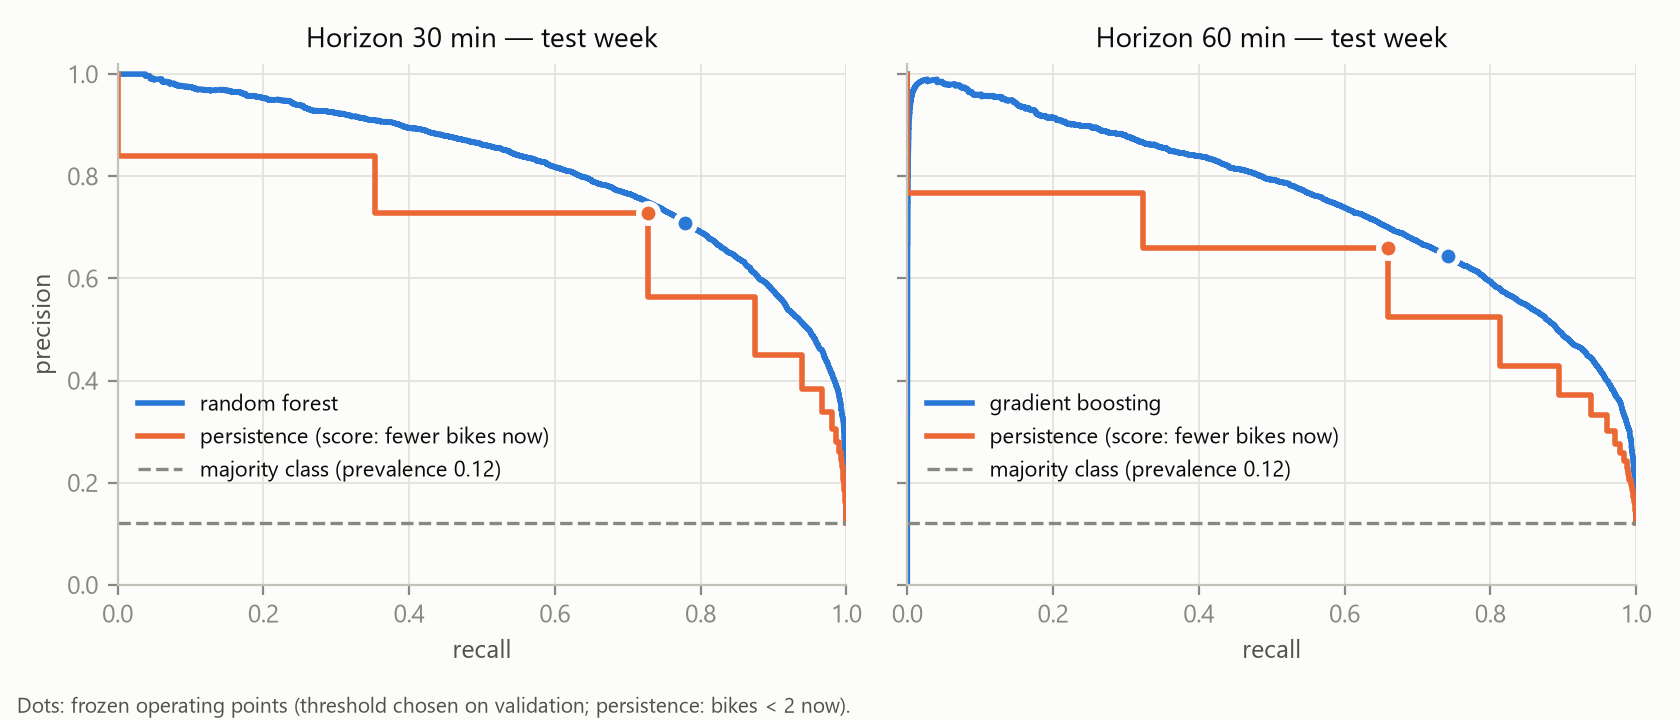

In [15]:
panels = {h: {"y": data[h]["test"]["y"].to_numpy(),
              "model": (selection[h]["chosen_model"], *outputs[h][selection[h]["chosen_model"]]),
              "persistence": outputs[h]["persistence"]} for h in HORIZONS}
Image(plots.pr_curves(panels, FIGURES / "pr_curves_test.png"), width=900)

Persistence's curve ranks samples by the current number of bikes (fewer bikes = higher risk). This graded score is
generous to the reference: with the binary rule alone, its PR-AUC would be much lower.

### Results by group, dispersion and uncertainty

* **By area, hour band (Paris time) and weekday / weekend.**
* **Day by day** on the test week: a dispersion measure that respects time.
* **Station bootstrap**: the 80 stations are resampled with replacement (rows of one station are dependent, so
  resampling rows would understate uncertainty). The paired difference model − persistence is computed on the same
  resampled stations.
* **Per station**: where the model loses to persistence.

In [16]:
scored = {}
for h in HORIZONS:
    te, chosen = data[h]["test"], selection[h]["chosen_model"]
    scored[h] = {name: ev.scored_frame(te, *outputs[h][name]) for name in (chosen, "persistence")}
    print(f"===== horizon {h} min =====")
    for by in ("area", "hour_band", "day_type"):
        display(pd.concat({name: ev.metrics_by(s, by)[GROUP_COLS] for name, s in scored[h].items()},
                          names=["model", by]).astype(float))

===== horizon 30 min =====


n  prevalence  pr_auc  precision  recall     f1
model         area                                                          
random forest Paris    37155.0       0.133   0.818      0.711   0.785  0.746
              suburbs  22419.0       0.103   0.812      0.702   0.765  0.732
persistence   Paris    37155.0       0.133   0.699      0.731   0.732  0.731
              suburbs  22419.0       0.103   0.708      0.725   0.721  0.723

n  prevalence  pr_auc  precision  recall     f1
model         hour_band                                                                 
random forest night 0-7h           17621.0       0.091   0.917      0.851   0.868  0.859
              morning peak 7-10h    7156.0       0.122   0.779      0.700   0.735  0.717
              day 10-17h           17574.0       0.154   0.824      0.708   0.808  0.755
              evening peak 17-20h   7656.0       0.144   0.688      0.592   0.663  0.626
              evening 20-24h        9567.0       0.101   0.720      0.634   0.720  0.675
persistence   night 0-7h           17621.0       0.091   0.849      0.865   0.855  0.860
              morning peak 7-10h    7156.0       0.122   0.664      0.710   0.672  0.691
              day 10-17h           17574.0       0.154   0.733      0.739   0.731  0.735
              evening peak 17-20h   7656.0       0.144   0.576      0.598   0.624  0.611
              evening 20-24h        9567.0       0.101   0.615      0.652   0.683  0.667

n  prevalence  pr_auc  precision  recall     f1
model         day_type                                                       
random forest weekday   44313.0       0.125   0.827      0.717   0.786  0.750
              weekend   15261.0       0.111   0.776      0.680   0.756  0.716
persistence   weekday   44313.0       0.125   0.709      0.735   0.735  0.735
              weekend   15261.0       0.111   0.677      0.707   0.706  0.707

===== horizon 60 min =====


n  prevalence  pr_auc  precision  recall     f1
model             area                                                          
gradient boosting Paris    37003.0       0.133   0.760      0.652   0.747  0.696
                  suburbs  22320.0       0.103   0.742      0.626   0.731  0.675
persistence       Paris    37003.0       0.133   0.613      0.657   0.658  0.658
                  suburbs  22320.0       0.103   0.633      0.665   0.664  0.665

n  prevalence  pr_auc  precision  recall     f1
model             hour_band                                                                 
gradient boosting night 0-7h           17511.0       0.091   0.869      0.800   0.806  0.803
                  morning peak 7-10h    7206.0       0.132   0.748      0.641   0.740  0.687
                  day 10-17h           17544.0       0.154   0.769      0.637   0.801  0.710
                  evening peak 17-20h   7656.0       0.137   0.571      0.525   0.597  0.558
                  evening 20-24h        9406.0       0.097   0.600      0.560   0.625  0.591
persistence       night 0-7h           17511.0       0.091   0.792      0.815   0.796  0.805
                  morning peak 7-10h    7206.0       0.132   0.576      0.634   0.555  0.592
                  day 10-17h           17544.0       0.154   0.666      0.684   0.678  0.681
                  evening peak 17-20h   7656.0       0.137   0.463      0.505   0.553  0.528
                  evening 20-24h        9406.0       0.097   0.506      0.553   0.601  0.576

n  prevalence  pr_auc  precision  recall     f1
model             day_type                                                       
gradient boosting weekday   44062.0       0.125   0.770      0.648   0.754  0.697
                  weekend   15261.0       0.111   0.700      0.629   0.704  0.665
persistence       weekday   44062.0       0.125   0.630      0.669   0.670  0.669
                  weekend   15261.0       0.111   0.583      0.630   0.628  0.629

In [17]:
for h in HORIZONS:
    chosen = selection[h]["chosen_model"]
    print(f"===== horizon {h} min =====")
    display(pd.concat({name: ev.daily_dispersion(s) for name, s in scored[h].items()}, names=["model", "day"]))
    display(ev.station_bootstrap(scored[h][chosen], scored[h]["persistence"], labels=(chosen, "persistence")))
    stations = ev.station_comparison(scored[h][chosen], scored[h]["persistence"])
    with_pos = stations[stations["positives"] > 0]
    print(f"{chosen} F1 >= persistence F1 on {(with_pos['f1_gain'] >= 0).mean():.0%} of the {len(with_pos)} stations "
          "with at least one positive; largest losses:")
    display(with_pos.head(5))

===== horizon 30 min =====


n  prevalence  pr_auc  precision  recall     f1
model         day                                                               
random forest 2026-10-01  7230.000       0.134   0.836      0.735   0.784  0.759
              2026-10-02  7680.000       0.143   0.819      0.728   0.787  0.757
              2026-10-03  7585.000       0.123   0.809      0.712   0.781  0.745
              2026-10-04  7676.000       0.099   0.729      0.643   0.725  0.682
              2026-10-05  7680.000       0.129   0.814      0.689   0.774  0.729
              2026-10-06  7680.000       0.113   0.792      0.670   0.758  0.712
              2026-10-07  7091.000       0.097   0.846      0.728   0.824  0.773
              2026-10-08  6952.000       0.136   0.859      0.750   0.797  0.773
              mean        7446.750       0.122   0.813      0.707   0.779  0.741
              std          305.474       0.017   0.040      0.036   0.029  0.032
              min         6952.000       0.097   0.729      0.643   0.725  0.682
              max         7680.000       0.143   0.859      0.750   0.824  0.773
persistence   2026-10-01  7230.000       0.134   0.721      0.740   0.734  0.737
              2026-10-02  7680.000       0.143   0.722      0.736   0.737  0.737
              2026-10-03  7585.000       0.123   0.719      0.732   0.732  0.732
              2026-10-04  7676.000       0.099   0.622      0.676   0.675  0.675
              2026-10-05  7680.000       0.129   0.691      0.723   0.728  0.725
              2026-10-06  7680.000       0.113   0.651      0.692   0.694  0.693
              2026-10-07  7091.000       0.097   0.735      0.764   0.773  0.768
              2026-10-08  6952.000       0.136   0.740      0.762   0.753  0.758
              mean        7446.750       0.122   0.700      0.728   0.728  0.728
              std          305.474       0.017   0.043      0.031   0.031  0.031
              min         6952.000       0.097   0.622      0.676   0.675  0.675
              max         7680.000       0.143   0.740      0.764   0.773  0.768

,mean,ci_low,ci_high
pr_auc (random forest),0.815,0.769,0.852
f1 (random forest),0.741,0.705,0.776
pr_auc (persistence),0.701,0.649,0.749
f1 (persistence),0.728,0.689,0.766
pr_auc (random forest - persistence),0.114,0.101,0.128
f1 (random forest - persistence),0.013,0.007,0.020


random forest F1 >= persistence F1 on 68% of the 69 stations with at least one positive; largest losses:


,n,positives,pr_auc,f1,pr_auc_reference,f1_reference,f1_gain
22014,746.0,4.0,0.177,0.000,0.139,0.250,-0.250
23009,746.0,4.0,0.326,0.000,0.271,0.250,-0.250
15052,746.0,7.0,0.600,0.615,0.533,0.714,-0.099
17027,746.0,25.0,0.227,0.182,0.195,0.240,-0.058
26008,746.0,23.0,0.396,0.304,0.304,0.348,-0.043


===== horizon 60 min =====


n  prevalence  pr_auc  precision  recall     f1
model             day                                                               
gradient boosting 2026-10-01  7200.000       0.134   0.786      0.670   0.749  0.707
                  2026-10-02  7679.000       0.143   0.754      0.651   0.722  0.685
                  2026-10-03  7585.000       0.123   0.736      0.649   0.727  0.686
                  2026-10-04  7676.000       0.100   0.652      0.605   0.676  0.638
                  2026-10-05  7680.000       0.129   0.741      0.614   0.727  0.666
                  2026-10-06  7680.000       0.113   0.730      0.616   0.742  0.673
                  2026-10-07  7029.000       0.096   0.794      0.633   0.798  0.706
                  2026-10-08  6794.000       0.138   0.822      0.703   0.803  0.749
                  mean        7415.375       0.122   0.752      0.643   0.743  0.689
                  std          356.176       0.017   0.052      0.033   0.041  0.033
                  min         6794.000       0.096   0.652      0.605   0.676  0.638
                  max         7680.000       0.143   0.822      0.703   0.803  0.749
persistence       2026-10-01  7200.000       0.134   0.653      0.689   0.684  0.686
                  2026-10-02  7679.000       0.143   0.634      0.660   0.664  0.662
                  2026-10-03  7585.000       0.123   0.630      0.656   0.658  0.657
                  2026-10-04  7676.000       0.100   0.525      0.598   0.592  0.595
                  2026-10-05  7680.000       0.129   0.596      0.637   0.642  0.639
                  2026-10-06  7680.000       0.113   0.569      0.623   0.628  0.626
                  2026-10-07  7029.000       0.096   0.659      0.693   0.702  0.698
                  2026-10-08  6794.000       0.138   0.681      0.720   0.705  0.713
                  mean        7415.375       0.122   0.618      0.659   0.659  0.659
                  std          356.176       0.017   0.052      0.040   0.038  0.039
                  min         6794.000       0.096   0.525      0.598   0.592  0.595
                  max         7680.000       0.143   0.681      0.720   0.705  0.713

,mean,ci_low,ci_high
pr_auc (gradient boosting),0.752,0.697,0.798
f1 (gradient boosting),0.689,0.645,0.730
pr_auc (persistence),0.618,0.561,0.671
f1 (persistence),0.659,0.614,0.702
pr_auc (gradient boosting - persistence),0.134,0.118,0.150
f1 (gradient boosting - persistence),0.030,0.019,0.040


gradient boosting F1 >= persistence F1 on 59% of the 69 stations with at least one positive; largest losses:


,n,positives,pr_auc,f1,pr_auc_reference,f1_reference,f1_gain
3007,744.0,15.0,0.476,0.0,0.497,0.645,-0.645
7009,744.0,30.0,0.365,0.0,0.432,0.600,-0.600
15052,744.0,7.0,0.165,0.0,0.251,0.429,-0.429
42505,744.0,14.0,0.349,0.0,0.343,0.429,-0.429
23009,744.0,4.0,0.392,0.0,0.148,0.250,-0.250


### Characteristic errors

Persistence is right by construction whenever the state does not change, and wrong on every change. Splitting the test
samples by *situation* (state now → state at `t + h`) shows where a model adds value: anticipating stations that
**become empty**, at the price of false alarms on stations that stay available.

,n,share of samples,predicted empty: random forest,predicted empty: persistence
situation,,,,
stays available,50355,0.845,0.009,0.0
becomes empty,1969,0.033,0.206,0.0
stays empty,5284,0.089,0.992,1.0
recovers,1966,0.033,0.950,1.0


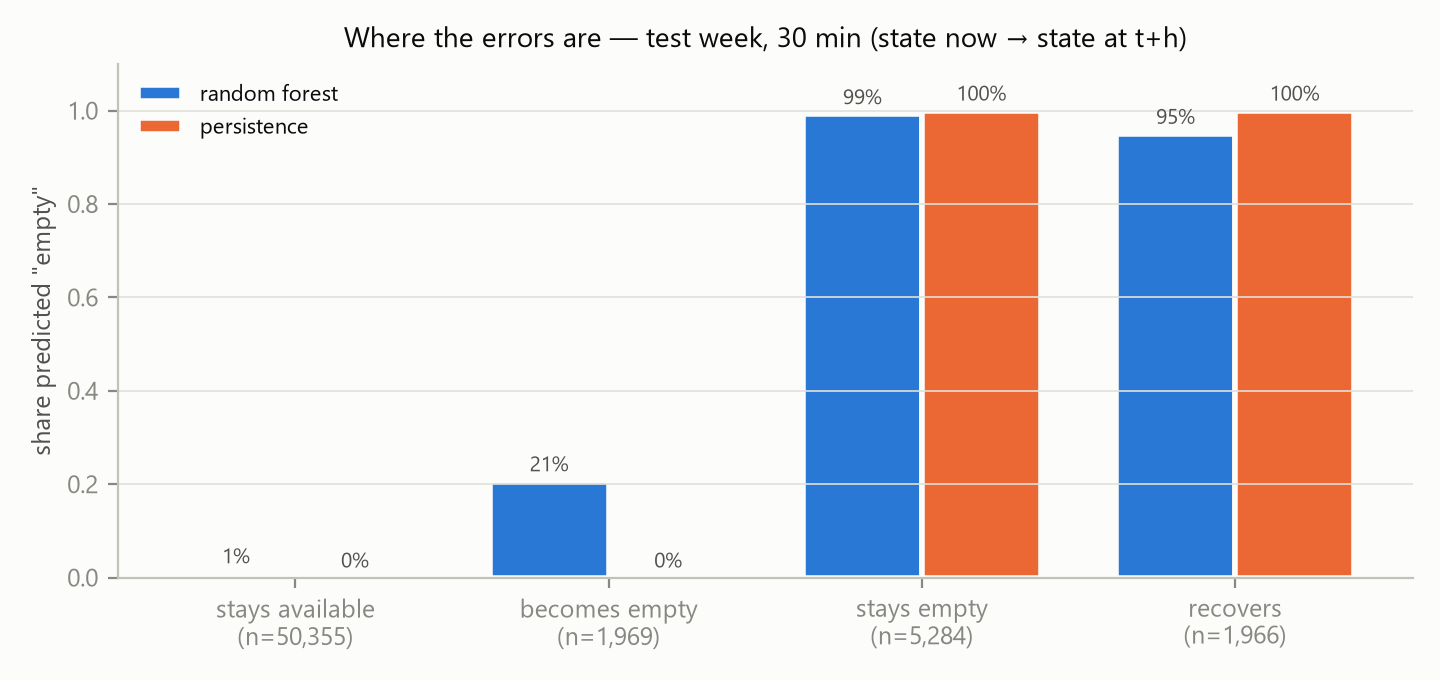

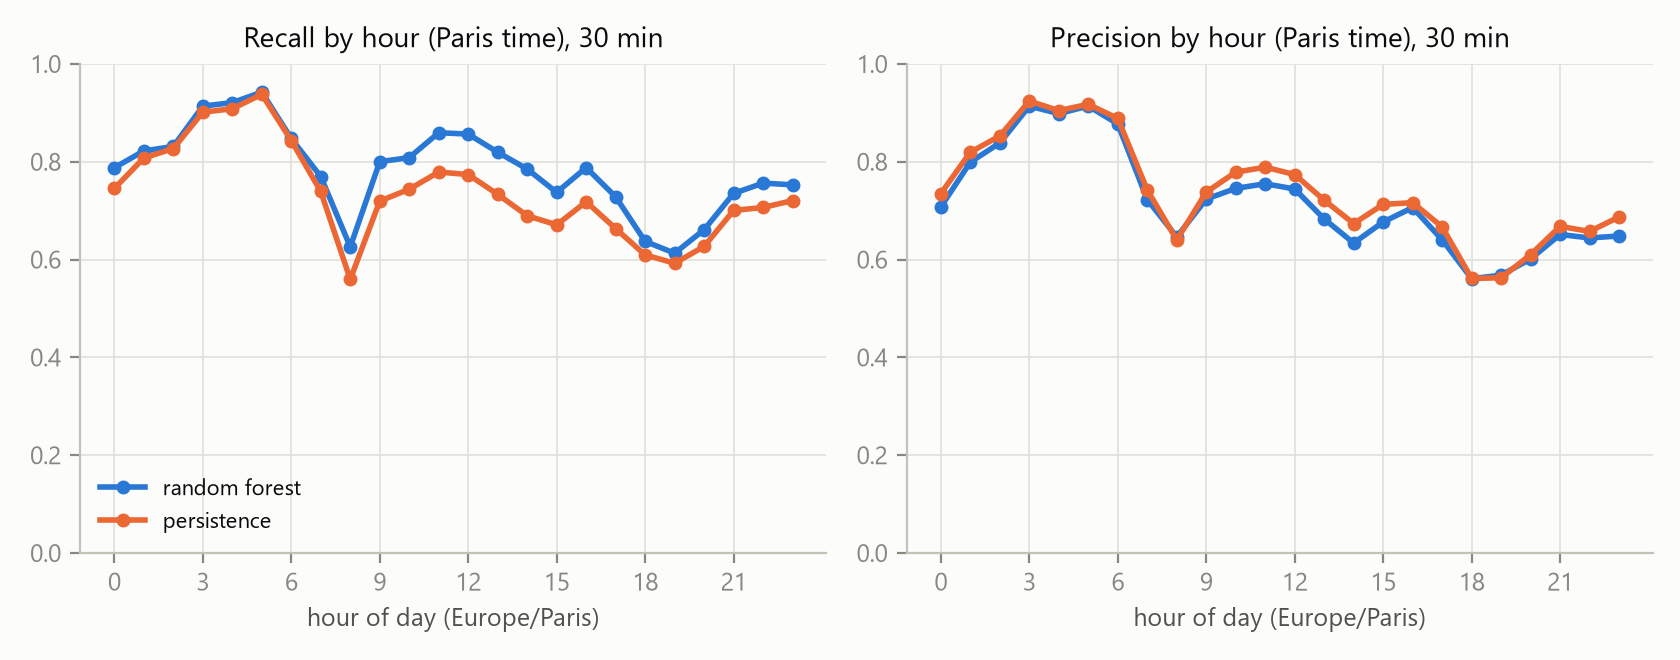

,n,share of samples,predicted empty: gradient boosting,predicted empty: persistence
situation,,,,
stays available,49642,0.837,0.019,0.0
becomes empty,2457,0.041,0.318,0.0
stays empty,4767,0.080,0.961,1.0
recovers,2457,0.041,0.826,1.0


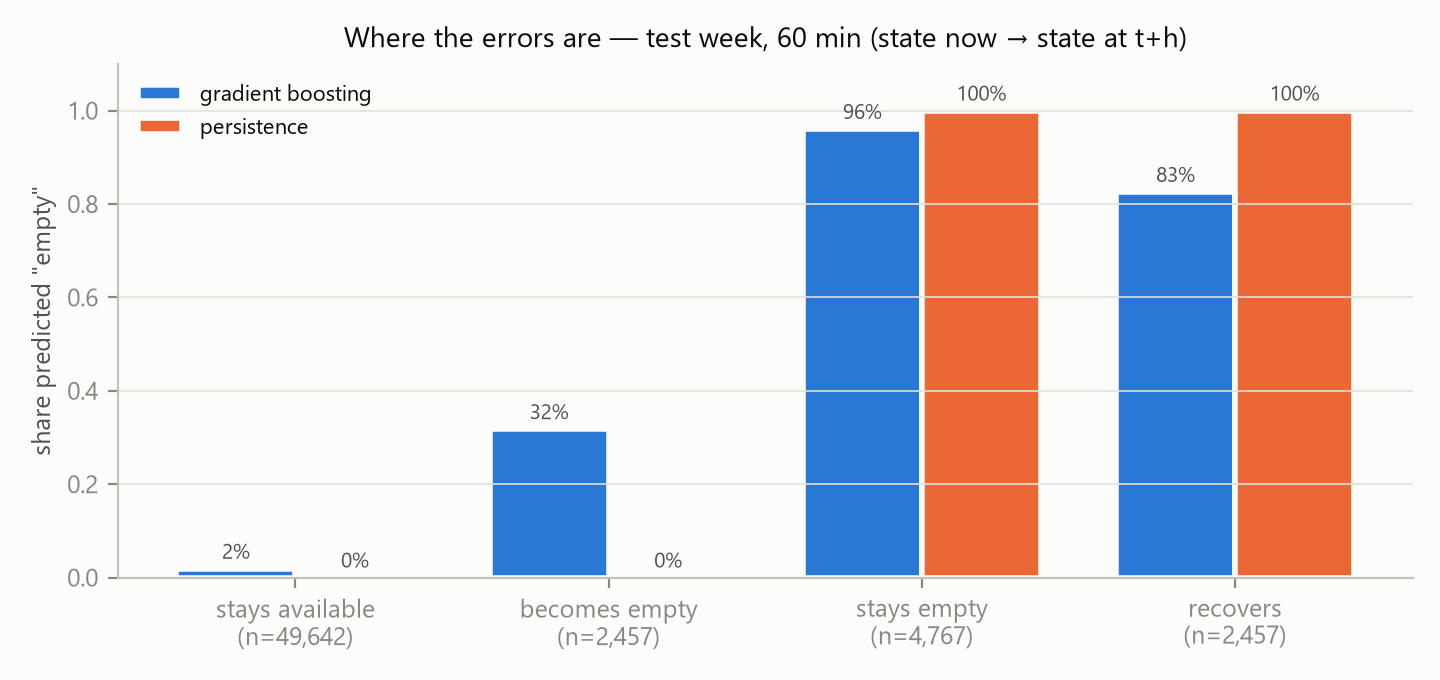

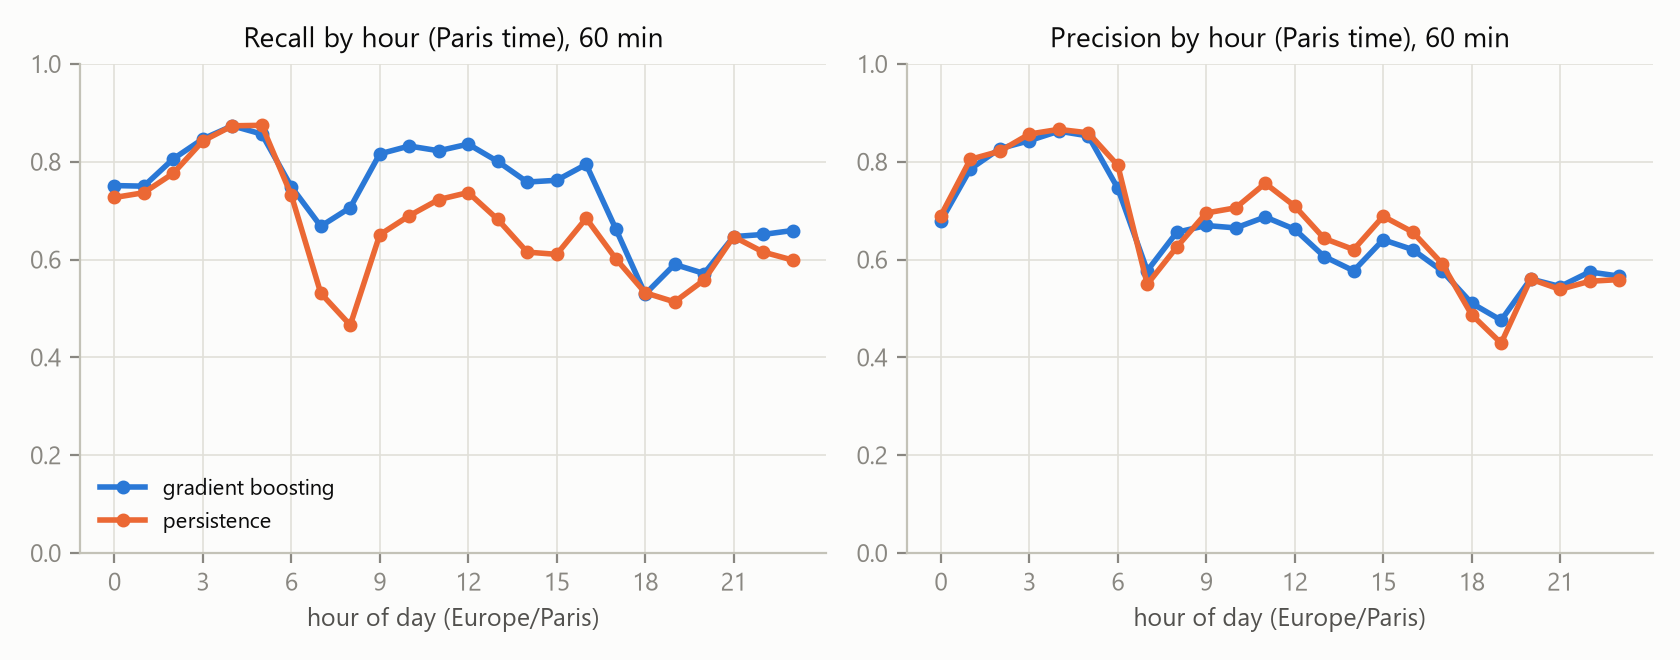

In [18]:
for h in HORIZONS:
    chosen = selection[h]["chosen_model"]
    table = ev.situation_table(scored[h])
    display(table)
    display(Image(plots.situations(table, chosen, h, FIGURES / f"situations_test_{h}min.png"), width=760))
    display(Image(plots.by_hour(chosen, scored[h][chosen], scored[h]["persistence"], h,
                                FIGURES / f"by_hour_test_{h}min.png"), width=880))

## 8. Sensitivity of the test results (frozen models)

* A closure at `t + h` counted as "departure impossible" instead of being excluded.
* Station 45504, which may be frozen in the feed, removed.

In [19]:
data_closed = build_all(grid, closed_as_positive=True)
for h in HORIZONS:
    keep = [f for f in fitted[h] if f.name in {selection[h]["chosen_model"], "persistence"}]
    te = data[h]["test"]
    variants = {"closure at t+h counted as positive": data_closed[h]["test"],
                f"without station {SUSPECT_STATION}": te[te.index.get_level_values("station_code") != SUSPECT_STATION]}
    for variant, d in variants.items():
        table, _ = evaluate(keep, d)
        print(f"horizon {h} min — {variant}: {len(d)} samples (default {len(te)})")
        display(table.drop(columns=["family"]).set_index("model"))

horizon 30 min — closure at t+h counted as positive: 59579 samples (default 59574)


,threshold,n,positives,prevalence,pr_auc,precision,recall,f1,tp,fp,fn,tn
model,,,,,,,,,,,,
persistence,NaN,59579,7258,0.122,0.702,0.729,0.728,0.729,5287,1966,1971,50355
random forest,0.339,59579,7258,0.122,0.816,0.708,0.779,0.742,5652,2329,1606,49992


horizon 30 min — without station 45504: 58825 samples (default 59574)


,threshold,n,positives,prevalence,pr_auc,precision,recall,f1,tp,fp,fn,tn
model,,,,,,,,,,,,
persistence,NaN,58825,7253,0.123,0.702,0.729,0.729,0.729,5284,1966,1969,49606
random forest,0.339,58825,7253,0.123,0.816,0.708,0.779,0.742,5649,2329,1604,49243


horizon 60 min — closure at t+h counted as positive: 59331 samples (default 59323)


,threshold,n,positives,prevalence,pr_auc,precision,recall,f1,tp,fp,fn,tn
model,,,,,,,,,,,,
persistence,NaN,59331,7232,0.122,0.619,0.660,0.659,0.660,4769,2457,2463,49642
gradient boosting,0.324,59331,7232,0.122,0.754,0.644,0.742,0.689,5363,2966,1869,49133


horizon 60 min — without station 45504: 58579 samples (default 59323)


,threshold,n,positives,prevalence,pr_auc,precision,recall,f1,tp,fp,fn,tn
model,,,,,,,,,,,,
persistence,NaN,58579,7224,0.123,0.619,0.660,0.660,0.660,4767,2457,2457,48898
gradient boosting,0.324,58579,7224,0.123,0.754,0.644,0.742,0.689,5361,2966,1863,48389


## 9. What the features really bring (ablation, validation)

A random forest is refitted without each feature group. The forest is used because it is stable across seeds;
gradient boosting's seed noise is as large as the smaller effects. Unlike permutation importance, refitting lets
correlated features stand in for each other: a small drop means *redundant*, not *useless*.

In [20]:
for h, sets in data.items():
    print(f"horizon {h} min")
    display(ablation(sets))

horizon 30 min


,n_features,val_pr_auc,delta_vs_all
configuration,,,
all features,16,0.828,0.000
without state,13,0.560,-0.268
without trend,12,0.818,-0.010
without calendar,12,0.807,-0.021
without station,11,0.821,-0.008
current state only,3,0.757,-0.071


horizon 60 min


,n_features,val_pr_auc,delta_vs_all
configuration,,,
all features,16,0.766,0.000e+00
without state,13,0.553,-2.130e-01
without trend,12,0.765,-7.052e-04
without calendar,12,0.722,-4.393e-02
without station,11,0.751,-1.493e-02
current state only,3,0.678,-8.795e-02


## 10. Appendix: exploratory experiments (validation only)

Redundant feature pairs, permutation importance of the chosen model (mean ± std over 5 repeats), sensitivity of the
two ensembles to the random seed (when two models are within a few thousandths of PR-AUC, one seed cannot rank
them), and PCA + naive Bayes / k-NN. Set `RUN_EXTRAS = True` in the first cell to run them
(`python scripts/run_pipeline.py --extras` does the same).

In [21]:
if RUN_EXTRAS:
    display(experiments.correlated_pairs(tr30).to_frame("r (train)"))
    for h in HORIZONS:
        chosen_model = next(f for f in fitted[h] if f.name == selection[h]["chosen_model"])
        print(f"horizon {h} min — permutation importance of {chosen_model.name} (validation sample)")
        display(experiments.permutation_importance_val(chosen_model, data[h]["val"]))
        print(f"horizon {h} min — validation PR-AUC over 5 seeds")
        display(experiments.seed_sensitivity(data[h]))
    display(experiments.pca_val(data[30], k=selection[30]["knn_k"]))
else:
    print("skipped (RUN_EXTRAS = False)")

skipped (RUN_EXTRAS = False)


## 11. Conclusions and limits

*Numbers below are those produced by this notebook and by `scripts/run_pipeline.py` (fixed seeds; the random forest's
multi-threaded predictions can differ in the 16th decimal between runs, which does not change any reported figure).*

**Answer to the question.** On the test week (1–8 October):

| horizon | model chosen on validation | PR-AUC model / persistence | F1 model / persistence | difference, 95 % station-bootstrap interval |
|---|---|---|---|---|
| 30 min | random forest | 0.816 / 0.702 | 0.742 / 0.729 | PR-AUC +0.114 [0.101; 0.128] · F1 +0.013 [0.007; 0.020] |
| 60 min | gradient boosting | 0.754 / 0.619 | 0.689 / 0.660 | PR-AUC +0.134 [0.118; 0.150] · F1 +0.030 [0.019; 0.040] |

The model mainly improves the **ranking** of stations by risk (PR-AUC). At persistence's own operating point the gain
is smaller: at the same recall, precision goes from 0.729 to 0.749 at 30 minutes and from 0.660 to 0.700 at 60
minutes. Persistence's PR-AUC is computed with a graded score (fewer bikes now = higher risk), which is generous to the
reference.

**Characteristic errors.**
* **Where the gain comes from.** Persistence is right whenever the state does not change, which covers 93 % of the test
  samples at 30 minutes. The model's value lies in the transitions. It anticipates about 21 % of the stations that
  *become* empty within 30 minutes (32 % at 60 minutes), which persistence misses by construction. It still predicts
  "empty" for 95 % of the empty stations that recover (persistence: 100 %).
* **By hour (Paris time).** Nights are easy (PR-AUC 0.92) and give no F1 gain over persistence. The evening peak,
  17–20 h, is the hardest band (PR-AUC 0.69).
* **By day.** Weekends are harder than weekdays (PR-AUC 0.78 vs 0.83). Day to day, the test F1 is 0.741 ± 0.032; it is
  lowest on Sunday 4 October, which is also the worst day for persistence.
* **By area and station.** Paris and suburban stations reach similar scores. Per station, the model's F1 is at least
  that of persistence on 68 % of the stations that have a positive on the test week (59 % at 60 minutes). The
  largest losses are on stations with very few positives (4 to 30 in the week).

**What the features bring** (validation, random forest refitted without each group).
* The current state is essential: −0.27 PR-AUC without it.
* The calendar group (mostly the hour of day) comes next: −0.02 at 30 minutes, −0.04 at 60 minutes.
* Station attributes add a little (−0.01 / −0.015), and so do recent trends (−0.01 at 30 minutes, nothing at 60).
* A model restricted to the current state (bikes, docks, fill ratio) already ranks better than persistence:
  validation PR-AUC 0.757 vs 0.707 at 30 minutes.

These are associations measured on this period, not effects.

**Model choice.** The random forest and gradient boosting are tied: over five seeds, gradient boosting's validation
PR-AUC varies by ±0.008 at 30 minutes, more than the gap between the two. Choosing on the five-seed mean selects the
same models. The depth-8 tree and the importance-weighted k-NN follow closely (test PR-AUC ≈ 0.80 at 30 minutes).
Plain k-NN and naive Bayes do not beat persistence on PR-AUC.

**Robustness.** Counting a closure at t + h as "departure impossible" adds 5 / 8 test samples and changes no metric at
three decimals. Removing station 45504, which may be frozen in the feed, changes nothing either: it has no positive.

**Limits of the collection.**
* Six weeks and 80 stations, in a single season (end of summer to beginning of autumn 2026).
* A 28-hour outage just before the validation week, so the 24-hour lag is missing on its first day.
* 36 incomplete snapshots, in which the same block of 30 or 50 stations is missing.
* Four stations closed for one to two days.
* One station (45504) that may be frozen in the feed.
* A source timestamp that is not a reliable freshness signal.
* A positive rate drifting upward week after week (10.3 % in train, 12.2 % in test).
* No weather, events or rebalancing information.

**Protocol caveat.** All choices were made on validation by fixed rules, and the test week was scored once by the final
code. However, during the audit of the first version of this project, the frozen first-version models were also
scored on the test week. The changes made afterwards each follow from the brief's rules or from training/validation
evidence, and the selection rule (best validation PR-AUC) is unchanged. They are listed in `reports/AUDIT.md`.

**Limits of use.** The model predicts an *observed state of the service* — the counts published by the feed — 30 or
60 minutes ahead, for these 80 stations, under the conditions of the collection period. It does not explain why a
station empties: departures, missing rebalancing and data errors cannot be told apart here. It is not a model of
individual users' demand. Any use on other stations, another season or another year would require a new evaluation.